# **Request Pool Analysis**

Composition, lengths and data-quality checks of the request pool. Tables are saved as CSV and figures as PDF and PNG in `data/request_pool/analysis_v2`.

## Setup

In [1]:
import json
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

POOL_VERSION = "v2"
POOL_DIR = "data/request_pool"

TABLE_DIR = os.path.join(POOL_DIR, f"analysis_{POOL_VERSION}", "tables")
FIGURE_DIR = os.path.join(POOL_DIR, f"analysis_{POOL_VERSION}", "figures")
os.makedirs(TABLE_DIR, exist_ok=True)
os.makedirs(FIGURE_DIR, exist_ok=True)

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_rows", 200)

pool = pd.read_parquet(os.path.join(POOL_DIR, f"request_pool_{POOL_VERSION}.parquet"))
with open(os.path.join(POOL_DIR, f"request_pool_{POOL_VERSION}_metadata.json")) as f:
    metadata = json.load(f)

SOURCES = list(metadata["sources"])
CELL_SIZE = metadata["cell_size"]
MAX_INPUT_TOKENS = metadata["max_input_tokens"]
print(f"Pool {POOL_VERSION}: {len(pool):,} requests from {pool['source'].nunique()} sources")

def save_table(df, name):
    # Saves a table as CSV for the thesis and returns it for display.
    df.to_csv(os.path.join(TABLE_DIR, f"{name}.csv"))
    return df

Mounted at /content/drive
Pool v2: 5,042 requests from 7 sources


### Figure style

Color-blind-safe categorical palette; every figure has a table with the same numbers.

In [2]:
SOURCE_COLORS = dict(zip(
    ["routerarena", "magpie", "math", "taco", "dolly", "longbench_v2", "longbench_v1"],
    ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#4a3aa7"],
))
MISSING_COLOR = "#c9c8c3"
TEXT = "#0b0b0b"
TEXT_SECONDARY = "#52514e"
GRID = "#e5e4df"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.edgecolor": GRID,
    "axes.labelcolor": TEXT_SECONDARY,
    "axes.titlecolor": TEXT,
    "axes.titlesize": 11,
    "axes.titleweight": "bold",
    "axes.labelsize": 9,
    "xtick.color": TEXT_SECONDARY,
    "ytick.color": TEXT_SECONDARY,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "legend.frameon": False,
    "legend.fontsize": 8,
    "font.size": 9,
})

def save_figure(fig, name):
    for ext in ("pdf", "png"):
        fig.savefig(os.path.join(FIGURE_DIR, f"{name}.{ext}"), dpi=200, bbox_inches="tight")
    plt.show()

## Build log

For each source: requests after the filters, sampling cells, requests sampled, removed as duplicates or over the token limit, and requests in the final pool.

In [3]:
build_log = pd.DataFrame({k: v for k, v in metadata["build_log"].items() if k in SOURCES}).T
build_log.loc["total"] = build_log.sum()
save_table(build_log, "build_log")

,available_after_source_filters,n_cells,sampled,removed_duplicates,removed_over_token_limit,final
routerarena,8400,39,1587,0,0,1587
magpie,296753,53,1932,0,0,1932
math,12498,5,250,0,0,250
taco,7070,5,250,0,0,250
dolly,15011,6,300,0,0,300
longbench_v2,377,14,334,0,61,273
longbench_v1,2468,9,450,0,0,450
total,342577,131,5103,0,61,5042


In [4]:
if "longbench_v2_filters" in metadata["build_log"]:
    print("LongBench v2 filters:", metadata["build_log"]["longbench_v2_filters"])
print("Cell size:", CELL_SIZE, "| cell columns:", metadata["cell_columns"])
print("Token limit:", f"{MAX_INPUT_TOKENS:,}", "| tokenizer:", metadata["tokenizer"])
print("Dataset revisions:")
for name, cfg in metadata["sources"].items():
    print(f"  {name:13s} {cfg['repo']:50s} {cfg['revision']}")

LongBench v2 filters: {'loaded': 503, 'removed_chinese': 10, 'removed_certainly_over_token_limit': 116}
Cell size: 50 | cell columns: ['task', 'domain', 'sampling_stratum']
Token limit: 128,000 | tokenizer: meta-llama/Llama-3.1-8B-Instruct
Dataset revisions:
  routerarena   RouteWorks/RouterArena                             a4a062ce3313b56bb09c042e1bc37b61d34e3bd8
  magpie        Magpie-Align/Magpie-Llama-3.1-Pro-300K-Filtered    1a982eea9ece373700dd8dfd04a4de08c2578c24
  math          EleutherAI/hendrycks_math                          21a5633873b6a120296cce3e2df9d5550074f4a3
  taco          XiaoBanni/TACO_with_solution                       c1d27565ce784104500854907dd35048c8d86b21
  dolly         databricks/databricks-dolly-15k                    bdd27f4d94b9c1f951818a7da7fd7aeea5dbff1a
  longbench_v2  zai-org/LongBench-v2                               2b48e494f2c7a2f0af81aae178e05c7e1dde0fe9
  longbench_v1  zai-org/LongBench                                  5e628be450b7e67fb7ae6e201b

## Composition

In [5]:
by_source_group = pd.crosstab(pool["source"], pool["task_group"], margins=True, margins_name="total")
save_table(by_source_group, "requests_by_source_and_task_group")

task_group,code,extraction,generation,qa,reasoning,summarization,translation,total
source,,,,,,,,
dolly,0,100,100,50,0,50,0,300
longbench_v1,0,0,0,150,150,150,0,450
longbench_v2,15,0,0,211,47,0,0,273
magpie,172,0,968,207,585,0,0,1932
math,0,0,0,0,250,0,0,250
routerarena,145,0,0,855,537,0,50,1587
taco,250,0,0,0,0,0,0,250
total,582,100,1068,1473,1569,200,50,5042


In [6]:
by_task = (pool.groupby(["task_group", "task"]).size().rename("n_requests")
               .reset_index().sort_values(["task_group", "n_requests"], ascending=[True, False]))
by_task["share_%"] = (100 * by_task["n_requests"] / len(pool)).round(1)
save_table(by_task.set_index(["task_group", "task"]), "requests_by_task")

n_requests  share_%
task_group    task                                       
code          code_generation                567     11.2
              code_understanding              15      0.3
extraction    classification                  50      1.0
              information_extraction          50      1.0
generation    creative_writing               205      4.1
              brainstorming                  203      4.0
              advice_seeking                 188      3.7
              role_playing                   162      3.2
              planning                       158      3.1
              editing                        152      3.0
qa            qa                            1026     20.3
              long_document_qa               408      8.1
              dialogue_qa                     39      0.8
reasoning     math_problem_solving           650     12.9
              reasoning                      495      9.8
              data_analysis                  233      4.6
              in_context_learning            191      3.8
summarization summarization                  200      4.0
translation   translation                     50      1.0

In [7]:
domain_label = pool["domain"].fillna("(to classify)")
by_source_domain = pd.crosstab(pool["source"], domain_label, margins=True, margins_name="total")
save_table(by_source_domain, "requests_by_source_and_domain")

domain,(to classify),coding,general,humanities,mathematics,natural_sciences,social_sciences,total
source,,,,,,,,
dolly,300,0,0,0,0,0,0,300
longbench_v1,450,0,0,0,0,0,0,450
longbench_v2,162,15,0,32,0,0,64,273
magpie,1510,172,0,0,250,0,0,1932
math,0,0,0,0,250,0,0,250
routerarena,0,289,276,405,182,150,285,1587
taco,0,250,0,0,0,0,0,250
total,2422,726,276,437,682,150,349,5042


In [8]:
missing_domain = (pool.assign(missing=pool["domain"].isna())
                      .groupby("source")["missing"].agg(n_missing="sum", share="mean"))
missing_domain.loc["total"] = [pool["domain"].isna().sum(), pool["domain"].isna().mean()]
missing_domain["share"] = (100 * missing_domain["share"]).round(1)
save_table(missing_domain.rename(columns={"share": "share_%"}), "missing_domain")

,n_missing,share_%
source,,
dolly,300.0,100.0
longbench_v1,450.0,100.0
longbench_v2,162.0,59.3
magpie,1510.0,78.2
math,0.0,0.0
routerarena,0.0,0.0
taco,0.0,0.0
total,2422.0,48.0


In [9]:
by_task_domain = pd.crosstab(pool["task"], domain_label)
save_table(by_task_domain, "requests_by_task_and_domain")

domain,(to classify),coding,general,humanities,mathematics,natural_sciences,social_sciences
task,,,,,,,
advice_seeking,188,0,0,0,0,0,0
brainstorming,203,0,0,0,0,0,0
classification,50,0,0,0,0,0,0
code_generation,0,567,0,0,0,0,0
code_understanding,0,15,0,0,0,0,0
creative_writing,205,0,0,0,0,0,0
data_analysis,159,0,0,0,0,0,74
dialogue_qa,39,0,0,0,0,0,0
editing,152,0,0,0,0,0,0


In [10]:
difficulty = (pool.groupby(["source", "difficulty_scale", "difficulty_raw"], dropna=False).size()
                  .rename("n_requests").reset_index())
save_table(difficulty.set_index(["source", "difficulty_scale", "difficulty_raw"]), "difficulty_by_source")

n_requests
source       difficulty_scale              difficulty_raw            
dolly        none                          NaN                    300
longbench_v1 none                          NaN                    450
longbench_v2 longbench_easy_hard           easy                   113
                                           hard                   160
magpie       magpie_very_easy_to_very_hard easy                   550
                                           hard                   545
                                           medium                 550
                                           very easy              197
                                           very hard               90
math         math_level_1_to_5             Level 1                 50
                                           Level 2                 50
                                           Level 3                 50
                                           Level 4                 50
                                           Level 5                 50
routerarena  routerarena_easy_medium_hard  easy                   536
                                           hard                   552
                                           medium                 499
taco         taco_easy_to_very_hard        EASY                    50
                                           HARD                    50
                                           MEDIUM                  50
                                           MEDIUM_HARD             50
                                           VERY_HARD               50

## Sampling cells

A cell is one (source, task, domain, stratum) combination with up to `CELL_SIZE` requests; smaller cells show where a source is thin.

In [11]:
cell_keys = ["source", "task", "domain", "sampling_stratum"]
cells = (pool[cell_keys].astype(object).fillna("<none>")
             .value_counts().rename("n_requests").reset_index())
cells["full"] = cells["n_requests"] >= CELL_SIZE

cell_summary = cells.groupby("source").agg(
    n_cells=("n_requests", "size"),
    full_cells=("full", "sum"),
    smallest_cell=("n_requests", "min"),
)
save_table(cell_summary, "cell_summary")

,n_cells,full_cells,smallest_cell
source,,,
dolly,6,6,50
longbench_v1,9,9,50
longbench_v2,14,0,3
magpie,53,35,1
math,5,5,50
routerarena,39,24,2
taco,5,5,50


In [12]:
small_cells = cells[~cells["full"]].sort_values(["source", "n_requests"])
print(f"{len(small_cells)} cells have fewer than {CELL_SIZE} requests (the source has no more):")
save_table(small_cells.set_index(cell_keys), "small_cells")

47 cells have fewer than 50 requests (the source has no more):


n_requests   full
source       task                domain          sampling_stratum                   
longbench_v2 data_analysis       <none>          hard                       3  False
                                                 easy                       3  False
             code_understanding  coding          easy                       6  False
                                                 hard                       9  False
             long_document_qa    humanities      easy                      13  False
             in_context_learning <none>          easy                      17  False
             long_document_qa    humanities      hard                      19  False
             dialogue_qa         <none>          hard                      19  False
                                                 easy                      20  False
             long_document_qa    social_sciences easy                      22  False
             in_context_learning <none>          hard                      24  False
             long_document_qa    <none>          easy                      32  False
                                 social_sciences hard                      42  False
                                 <none>          hard                      44  False
magpie       data_analysis       <none>          very hard                  1  False
             brainstorming       <none>          very hard                  1  False
                                                 very easy                  2  False
             code_generation     coding          very hard                  2  False
             data_analysis       <none>          very easy                  2  False
             creative_writing    <none>          very hard                  2  False
                                                 very easy                  3  False
             role_playing        <none>          very hard                  3  False
             advice_seeking      <none>          very hard                  5  False
             qa                  <none>          very hard                  7  False
             editing             <none>          very easy                  7  False
             planning            <none>          very easy                  8  False
             role_playing        <none>          very easy                  9  False
             reasoning           <none>          very easy                 13  False
                                                 very hard                 19  False
             code_generation     coding          very easy                 20  False
             advice_seeking      <none>          very easy                 33  False
             editing             <none>          hard                      45  False
routerarena  qa                  mathematics     medium                     2  False
             reasoning           social_sciences hard                       5  False
                                                 medium                     9  False
             data_analysis       social_sciences easy                       9  False
             long_document_qa    humanities      medium                    14  False
             reasoning           humanities      hard                      19  False
             long_document_qa    humanities      easy                      22  False
             data_analysis       social_sciences medium                    24  False
             qa                  mathematics     easy                      30  False
             reasoning           general         easy                      33  False
             data_analysis       social_sciences hard                      41  False
             qa                  general         hard                      43  False
                                 coding          hard                      44  False
             code_generation     coding          easy                   

## Lengths

Output length is available only where the source provides a realistic reference answer.

In [13]:
input_stats = pool.groupby("source")["input_tokens"].describe(percentiles=[0.1, 0.5, 0.9, 0.99]).round(0)
input_stats.loc["all"] = pool["input_tokens"].describe(percentiles=[0.1, 0.5, 0.9, 0.99]).round(0)
save_table(input_stats, "input_tokens_by_source")

,count,mean,std,min,10%,50%,90%,99%,max
source,,,,,,,,,
dolly,300.0,124.0,371.0,3.0,8.0,31.0,260.0,692.0,5507.0
longbench_v1,450.0,8849.0,5023.0,470.0,2917.0,7986.0,15993.0,21061.0,27047.0
longbench_v2,273.0,58356.0,37542.0,10032.0,16577.0,46207.0,116169.0,126814.0,126839.0
magpie,1932.0,127.0,156.0,5.0,21.0,66.0,323.0,805.0,986.0
math,250.0,62.0,63.0,8.0,19.0,44.0,120.0,357.0,512.0
routerarena,1587.0,275.0,373.0,8.0,30.0,108.0,789.0,1579.0,4729.0
taco,250.0,518.0,215.0,56.0,277.0,490.0,807.0,1194.0,1310.0
all,5042.0,4121.0,15901.0,3.0,24.0,110.0,7566.0,99278.0,126839.0


In [14]:
EDGES = [0, 64, 256, 1_024, 4_096, 16_384, 65_536]
LENGTH_BINS = [e for e in EDGES if e < MAX_INPUT_TOKENS] + [MAX_INPUT_TOKENS]

def short(n):
    return f"{n // 1000}k" if n >= 1000 else str(n)

LENGTH_LABELS = [f"{short(a + 1) if a else 1}–{short(b)}" for a, b in zip(LENGTH_BINS[:-1], LENGTH_BINS[1:])]
length_band = pd.cut(pool["input_tokens"], LENGTH_BINS, labels=LENGTH_LABELS)
by_length = pd.crosstab(pool["source"], length_band, margins=True, margins_name="total")
save_table(by_length, "requests_by_input_length_band")

input_tokens,1–64,65–256,257–1k,1k–4k,4k–16k,16k–65k,65k–128k,total
source,,,,,,,,
dolly,183,86,28,2,1,0,0,300
longbench_v1,0,0,3,78,338,31,0,450
longbench_v2,0,0,0,0,25,136,112,273
magpie,953,719,260,0,0,0,0,1932
math,182,62,6,0,0,0,0,250
routerarena,626,448,431,81,1,0,0,1587
taco,1,21,223,5,0,0,0,250
total,1945,1336,951,166,365,167,112,5042


In [15]:
output_stats = pool.groupby("source")["reference_output_tokens"].agg(
    coverage=lambda s: round(100 * s.notna().mean(), 1),
    median="median", p90=lambda s: s.quantile(0.9), max="max",
)
save_table(output_stats.rename(columns={"coverage": "coverage_%"}), "reference_output_tokens_by_source")

,coverage_%,median,p90,max
source,,,,
dolly,100.0,50.0,194.8,1661.0
longbench_v1,33.3,302.0,796.1,1416.0
longbench_v2,0.0,NaN,NaN,NaN
magpie,100.0,523.0,814.8,4070.0
math,100.0,129.5,320.8,1363.0
routerarena,3.2,53.0,190.0,315.0
taco,100.0,209.5,647.9,14689.0


## Data-quality checks

In [16]:
CJK_RE = re.compile(r"[぀-ヿ㐀-䶿一-鿿가-힯]")

def cjk_ratio(text, sample_chars=20_000):
    sample = text[:sample_chars]
    return len(CJK_RE.findall(sample)) / max(len(sample), 1)

normalized = pool["text"].str.lower().str.split().str.join(" ")
checks = pd.Series({
    "requests": len(pool),
    "duplicate texts": int(normalized.duplicated().sum()),
    "empty texts": int((pool["text"].str.strip() == "").sum()),
    "texts mostly in CJK script (> 5%)": int(pool["text"].map(cjk_ratio).gt(0.05).sum()),
    "requests over the token limit": int((pool["input_tokens"] > MAX_INPUT_TOKENS).sum()),
    "requests without task_group": int(pool["task_group"].isna().sum()),
    "translation requests without instruction":
        int((~pool.loc[pool["task"] == "translation", "text"].str.startswith("Translate")).sum()),
}, name="count")
save_table(checks.to_frame(), "quality_checks")

,count
requests,5042
duplicate texts,0
empty texts,0
texts mostly in CJK script (> 5%),1
requests over the token limit,0
requests without task_group,0
translation requests without instruction,0


In [17]:
print("Shortest requests (kept: realistic short prompts):")
pool.nsmallest(10, "input_tokens")[["request_id", "task", "input_tokens", "text"]]

Shortest requests (kept: realistic short prompts):


,request_id,task,input_tokens,text
1343,dolly-00120,creative_writing,3,Write about apple
1234,dolly-00011,brainstorming,4,ways to generate electricity
1441,dolly-00218,qa,4,What are tacos?
1456,dolly-00233,qa,4,What is SSL?
1247,dolly-00024,brainstorming,5,Are universities becoming obsolete ?
1429,dolly-00206,qa,5,What is ClassRanked?
1444,dolly-00221,qa,5,What is MapReduce?
1461,dolly-00238,qa,5,is sales a great career
3094,magpie-01571,qa,5,What is gamification?
3103,magpie-01580,qa,5,What is green tea?


In [18]:
print("One example per task (first 300 characters):")
examples = pool.groupby("task").sample(1, random_state=0)[["task", "source", "difficulty_raw", "input_tokens", "text"]]
examples["text"] = examples["text"].str.slice(0, 300)
examples.set_index("task")

One example per task (first 300 characters):


,source,difficulty_raw,input_tokens,text
task,,,,
advice_seeking,magpie,medium,42,The sudden loss of a loved one is a traumatic ...
brainstorming,magpie,hard,157,I am trying to create a mask to wear while exe...
classification,dolly,None,52,"There are many different types, styles and gen..."
code_generation,taco,MEDIUM,233,Given is a positive integer N. Consider repeat...
code_understanding,longbench_v2,hard,48514,"HASURA_GRAPHQL_JWT_SECRET={""type"":""HS256"", ""ke..."
creative_writing,magpie,medium,331,A Previously Unseen Shakespearean Manuscript\n...
data_analysis,magpie,easy,27,"# Given an array of integers, return a hash wh..."
dialogue_qa,longbench_v2,hard,38796,"{\n ""meta"": {\n ""name_exp"": ""public_goods""..."
editing,magpie,hard,146,Recover Password violates section 9 of our IoT...


## Figures

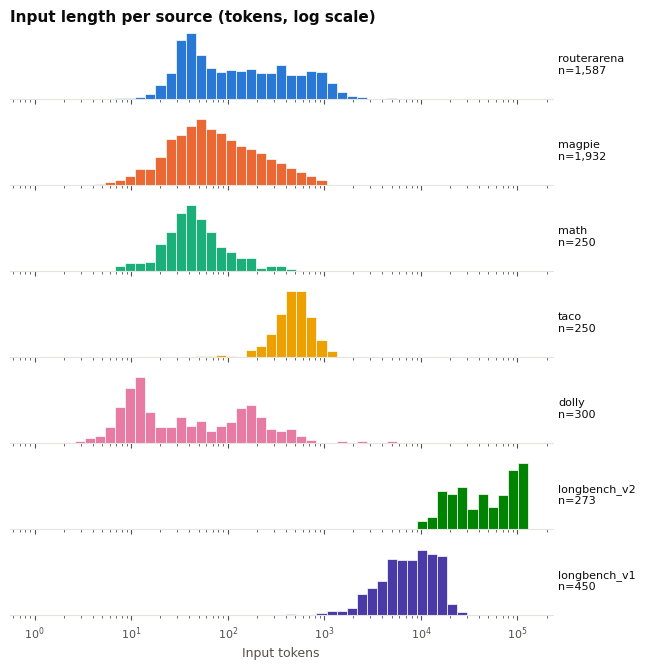

In [ ]:
# input length per source, small multiples on a shared logarithmic axis
sources = [s for s in SOURCE_COLORS if s in set(pool["source"])]
bins = np.logspace(0, np.log10(MAX_INPUT_TOKENS), 50)

fig, axes = plt.subplots(len(sources), 1, figsize=(7, 1.0 * len(sources) + 0.6), sharex=True)
for ax, source in zip(axes, sources):
    values = pool.loc[pool["source"] == source, "input_tokens"]
    ax.hist(values, bins=bins, color=SOURCE_COLORS[source], edgecolor="white", linewidth=0.5)
    ax.set_xscale("log")
    ax.set_yticks([])
    ax.spines["left"].set_visible(False)
    ax.text(1.01, 0.5, f"{source}\nn={len(values):,}", transform=ax.transAxes,
            va="center", ha="left", fontsize=8, color=TEXT)
axes[0].set_title("Input length per source (tokens, log scale)", loc="left")
axes[-1].set_xlabel("Input tokens")
fig.subplots_adjust(hspace=0.25)
save_figure(fig, "fig_input_tokens_by_source")

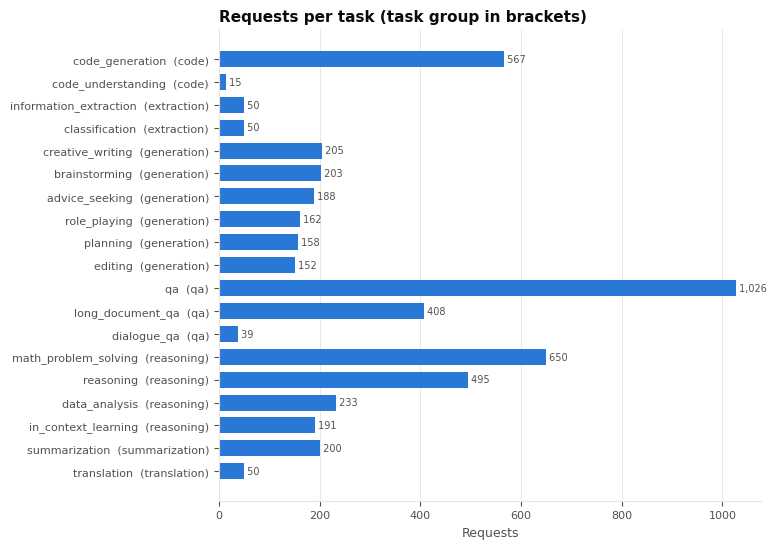

In [ ]:
# requests per task, grouped by task group
order = by_task.sort_values(["task_group", "n_requests"], ascending=[False, True])
fig, ax = plt.subplots(figsize=(7, 0.28 * len(order) + 0.8))
ax.barh(order["task"], order["n_requests"], color=SOURCE_COLORS["routerarena"], height=0.7)
for y, (n, group) in enumerate(zip(order["n_requests"], order["task_group"])):
    ax.text(n, y, f" {n:,}", va="center", fontsize=7, color=TEXT_SECONDARY)
ax.set_yticks(range(len(order)), [f"{t}  ({g})" for t, g in zip(order["task"], order["task_group"])])
ax.set_xlabel("Requests")
ax.set_title("Requests per task (task group in brackets)", loc="left")
ax.xaxis.grid(True, color=GRID, linewidth=0.6)
ax.set_axisbelow(True)
save_figure(fig, "fig_requests_by_task")

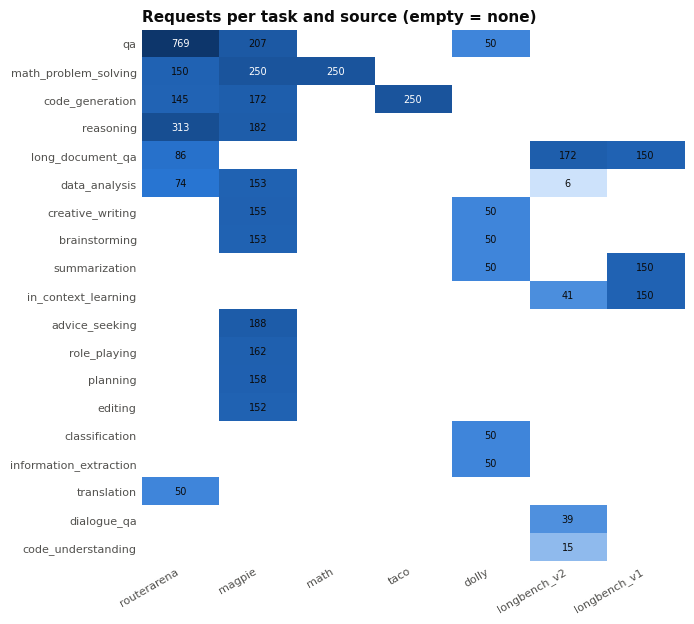

In [ ]:
# task by source, as a matrix of counts
matrix = pd.crosstab(pool["task"], pool["source"]).reindex(columns=sources, fill_value=0)
matrix = matrix.loc[matrix.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(7, 0.3 * len(matrix) + 1.2))
masked = np.ma.masked_equal(matrix.values, 0)
cmap = plt.matplotlib.colors.LinearSegmentedColormap.from_list("blue", ["#cde2fb", "#2a78d6", "#0d366b"])
ax.imshow(np.ma.log10(masked), cmap=cmap, aspect="auto")
for (i, j), n in np.ndenumerate(matrix.values):
    if n:
        ax.text(j, i, f"{n:,}", ha="center", va="center", fontsize=7,
                color="white" if n >= 0.3 * matrix.values.max() else TEXT)
ax.set_xticks(range(len(sources)), sources, rotation=30, ha="right")
ax.set_yticks(range(len(matrix)), matrix.index)
for side in ("left", "bottom"):
    ax.spines[side].set_visible(False)
ax.tick_params(length=0)
ax.set_title("Requests per task and source (empty = none)", loc="left")
save_figure(fig, "fig_task_by_source")

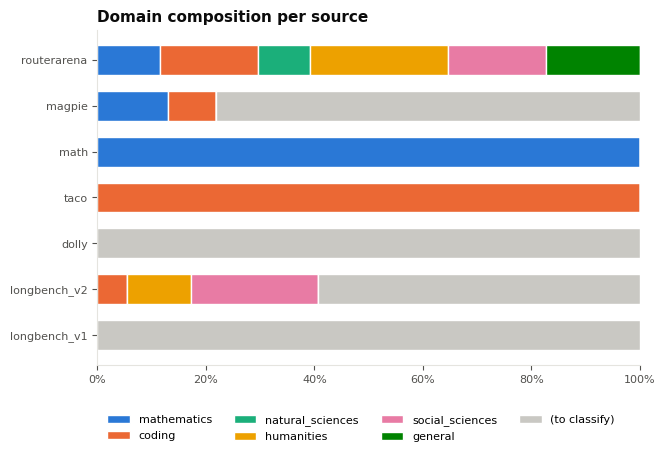

In [ ]:
# domain composition per source; gray marks requests still to be classified
domain_order = [d for d in ["mathematics", "coding", "natural_sciences", "humanities",
                            "social_sciences", "general"] if d in set(pool["domain"].dropna())]
DOMAIN_COLORS = dict(zip(domain_order, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
shares = pd.crosstab(pool["source"], domain_label, normalize="index").reindex(sources)

fig, ax = plt.subplots(figsize=(7, 0.45 * len(sources) + 1.2))
left = np.zeros(len(sources))
for domain in domain_order + ["(to classify)"]:
    if domain not in shares:
        continue
    width = shares[domain].values
    ax.barh(sources, width, left=left, height=0.65, label=domain,
            color=DOMAIN_COLORS.get(domain, MISSING_COLOR), edgecolor="white", linewidth=1)
    left += width
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
ax.set_title("Domain composition per source", loc="left")
ax.legend(ncol=4, loc="upper left", bbox_to_anchor=(0, -0.12))
save_figure(fig, "fig_domain_by_source")

## Saved files

In [23]:
for folder in (TABLE_DIR, FIGURE_DIR):
    print(folder)
    for name in sorted(os.listdir(folder)):
        print("  ", name)

/content/drive/MyDrive/TESI/request_pool/analysis_v2/tables
   build_log.csv
   cell_summary.csv
   difficulty_by_source.csv
   input_tokens_by_source.csv
   missing_domain.csv
   quality_checks.csv
   reference_output_tokens_by_source.csv
   requests_by_input_length_band.csv
   requests_by_source_and_domain.csv
   requests_by_source_and_task_group.csv
   requests_by_task.csv
   requests_by_task_and_domain.csv
   small_cells.csv
/content/drive/MyDrive/TESI/request_pool/analysis_v2/figures
   fig_domain_by_source.pdf
   fig_domain_by_source.png
   fig_input_tokens_by_source.pdf
   fig_input_tokens_by_source.png
   fig_requests_by_task.pdf
   fig_requests_by_task.png
   fig_task_by_source.pdf
   fig_task_by_source.png
